In [ ]:
!nvidia-smi

Sat Sep 26 09:47:24 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!nvcc --version

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Fri_Feb_21_20:23:50_PST_2025
Cuda compilation tools, release 12.8, V12.8.93
Build cuda_12.8.r12.8/compiler.35583870_0


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cu128
CUDA available: True


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

image = np.random.randint(0, 256, (512, 512)).astype(np.float32)

print("Image shape:", image.shape)

Image shape: (512, 512)


In [ ]:
kernel = np.array([
    [-1, -1, -1],
    [ 0,  0,  0],
    [ 1,  1,  1]
], dtype=np.float32)

print(kernel)

[[-1. -1. -1.]
 [ 0.  0.  0.]
 [ 1.  1.  1.]]


In [ ]:
def convolution_cpu(image, kernel):
    image_height, image_width = image.shape
    kernel_height, kernel_width = kernel.shape

    output_height = image_height - kernel_height + 1
    output_width = image_width - kernel_width + 1

    output = np.zeros((output_height, output_width), dtype=np.float32)

    for i in range(output_height):
        for j in range(output_width):
            region = image[
                i:i + kernel_height,
                j:j + kernel_width
            ]

            output[i, j] = np.sum(region * kernel)

    return output

In [ ]:
output = convolution_cpu(image, kernel)

print("Input shape:", image.shape)
print("Output shape:", output.shape)

Input shape: (512, 512)
Output shape: (510, 510)


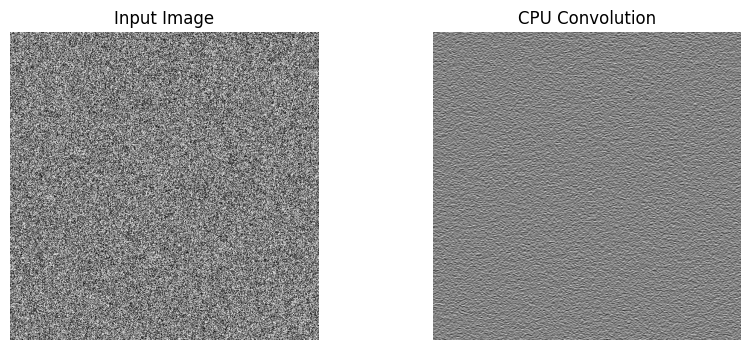

In [ ]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output, cmap="gray")
plt.title("CPU Convolution")
plt.axis("off")

plt.show()

In [ ]:
import time

start = time.perf_counter()

output = convolution_cpu(image, kernel)

end = time.perf_counter()

cpu_time = end - start

print(f"CPU execution time: {cpu_time:.6f} seconds")

CPU execution time: 1.847371 seconds


In [ ]:
print("CPU output shape:", output.shape)
print("CPU execution time:", cpu_time, "seconds")

CPU output shape: (510, 510)
CPU execution time: 1.847370905000048 seconds


In [ ]:
%%writefile thread_demo.cu

#include <stdio.h>
#include <cuda_runtime.h>

__global__ void threadDemo() {
    int globalId = blockIdx.x * blockDim.x + threadIdx.x;

    printf("Block: %d, Thread: %d, Global ID: %d\n",
           blockIdx.x, threadIdx.x, globalId);
}

int main() {
    threadDemo<<<2, 4>>>();

    cudaDeviceSynchronize();

    return 0;
}

Writing thread_demo.cu


In [ ]:
!nvcc thread_demo.cu -o thread_demo

nvcc warning : Support for offline compilation for architectures prior to '<compute/sm/lto>_75' will be removed in a future release (Use -Wno-deprecated-gpu-targets to suppress warning).


In [ ]:
!./thread_demo

Block: 0, Thread: 0, Global ID: 0
Block: 0, Thread: 1, Global ID: 1
Block: 0, Thread: 2, Global ID: 2
Block: 0, Thread: 3, Global ID: 3
Block: 1, Thread: 0, Global ID: 4
Block: 1, Thread: 1, Global ID: 5
Block: 1, Thread: 2, Global ID: 6
Block: 1, Thread: 3, Global ID: 7


In [ ]:
%%writefile convolution.cu

#include <stdio.h>
#include <cuda_runtime.h>

__global__ void convolutionKernel(float *image, float *kernel, float *output,
                                  int width, int height,
                                  int kernelSize) {

    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;

    int outputWidth = width - kernelSize + 1;
    int outputHeight = height - kernelSize + 1;

    if (x < outputWidth && y < outputHeight) {

        float sum = 0.0f;

        for (int i = 0; i < kernelSize; i++) {
            for (int j = 0; j < kernelSize; j++) {

                int imageX = x + j;
                int imageY = y + i;

                sum += image[imageY * width + imageX]
                       * kernel[i * kernelSize + j];
            }
        }

        output[y * outputWidth + x] = sum;
    }
}

int main() {

    int width = 512;
    int height = 512;
    int kernelSize = 3;

    int outputWidth = width - kernelSize + 1;
    int outputHeight = height - kernelSize + 1;

    size_t imageSize = width * height * sizeof(float);
    size_t kernelSizeBytes = kernelSize * kernelSize * sizeof(float);
    size_t outputSize = outputWidth * outputHeight * sizeof(float);

    float *h_image = new float[width * height];
    float h_kernel[9] = {
        -1, -1, -1,
         0,  0,  0,
         1,  1,  1
    };
    float *h_output = new float[outputWidth * outputHeight];

    for (int i = 0; i < width * height; i++) {
        h_image[i] = (float)(i % 256);
    }

    float *d_image, *d_kernel, *d_output;

    cudaMalloc(&d_image, imageSize);
    cudaMalloc(&d_kernel, kernelSizeBytes);
    cudaMalloc(&d_output, outputSize);

    cudaMemcpy(d_image, h_image, imageSize, cudaMemcpyHostToDevice);
    cudaMemcpy(d_kernel, h_kernel, kernelSizeBytes, cudaMemcpyHostToDevice);

    dim3 blockSize(16, 16);

    dim3 gridSize(
        (outputWidth + blockSize.x - 1) / blockSize.x,
        (outputHeight + blockSize.y - 1) / blockSize.y
    );

    convolutionKernel<<<gridSize, blockSize>>>(
        d_image, d_kernel, d_output,
        width, height, kernelSize
    );

    cudaDeviceSynchronize();

    cudaMemcpy(h_output, d_output, outputSize, cudaMemcpyDeviceToHost);

    printf("Input size: %d x %d\n", width, height);
    printf("Output size: %d x %d\n", outputWidth, outputHeight);
    printf("First output value: %f\n", h_output[0]);

    cudaFree(d_image);
    cudaFree(d_kernel);
    cudaFree(d_output);

    delete[] h_image;
    delete[] h_output;

    return 0;
}

Writing convolution.cu


In [ ]:
!nvcc convolution.cu -o convolution

nvcc warning : Support for offline compilation for architectures prior to '<compute/sm/lto>_75' will be removed in a future release (Use -Wno-deprecated-gpu-targets to suppress warning).


In [ ]:
!./convolution

Input size: 512 x 512
Output size: 510 x 510
First output value: 0.000000


In [ ]:
cuda_image = np.arange(512 * 512, dtype=np.float32).reshape(512, 512) % 256

cuda_cpu_output = convolution_cpu(cuda_image, kernel)

print("CPU output shape:", cuda_cpu_output.shape)
print("First CPU output value:", cuda_cpu_output[0, 0])

CPU output shape: (510, 510)
First CPU output value: 0.0


In [ ]:
%%writefile convolution.cu

#include <stdio.h>
#include <cuda_runtime.h>

__global__ void convolutionKernel(float *image, float *kernel, float *output,
                                  int width, int height, int kernelSize) {

    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;

    int outputWidth = width - kernelSize + 1;
    int outputHeight = height - kernelSize + 1;

    if (x < outputWidth && y < outputHeight) {

        float sum = 0.0f;

        for (int i = 0; i < kernelSize; i++) {
            for (int j = 0; j < kernelSize; j++) {

                int imageX = x + j;
                int imageY = y + i;

                sum += image[imageY * width + imageX]
                       * kernel[i * kernelSize + j];
            }
        }

        output[y * outputWidth + x] = sum;
    }
}

int main() {

    int width = 512;
    int height = 512;
    int kernelSize = 3;

    int outputWidth = width - kernelSize + 1;
    int outputHeight = height - kernelSize + 1;

    size_t imageSize = width * height * sizeof(float);
    size_t kernelBytes = kernelSize * kernelSize * sizeof(float);
    size_t outputSize = outputWidth * outputHeight * sizeof(float);

    float *h_image = new float[width * height];

    float h_kernel[9] = {
        -1, -1, -1,
         0,  0,  0,
         1,  1,  1
    };

    float *h_output = new float[outputWidth * outputHeight];

    for (int i = 0; i < width * height; i++) {
        h_image[i] = (float)(i % 256);
    }

    float *d_image;
    float *d_kernel;
    float *d_output;

    cudaMalloc(&d_image, imageSize);
    cudaMalloc(&d_kernel, kernelBytes);
    cudaMalloc(&d_output, outputSize);

    cudaMemcpy(d_image, h_image, imageSize, cudaMemcpyHostToDevice);
    cudaMemcpy(d_kernel, h_kernel, kernelBytes, cudaMemcpyHostToDevice);

    dim3 blockSize(16, 16);

    dim3 gridSize(
        (outputWidth + blockSize.x - 1) / blockSize.x,
        (outputHeight + blockSize.y - 1) / blockSize.y
    );

    cudaEvent_t start, stop;

    cudaEventCreate(&start);
    cudaEventCreate(&stop);

    // Warm-up
    convolutionKernel<<<gridSize, blockSize>>>(
        d_image,
        d_kernel,
        d_output,
        width,
        height,
        kernelSize
    );

    cudaDeviceSynchronize();

    // Start timing
    cudaEventRecord(start);

    // Timed kernel
    convolutionKernel<<<gridSize, blockSize>>>(
        d_image,
        d_kernel,
        d_output,
        width,
        height,
        kernelSize
    );

    // Stop timing
    cudaEventRecord(stop);

    cudaEventSynchronize(stop);

    float gpuTime = 0.0f;

    cudaEventElapsedTime(&gpuTime, start, stop);

    cudaMemcpy(
        h_output,
        d_output,
        outputSize,
        cudaMemcpyDeviceToHost
    );

    printf("Input size: %d x %d\n", width, height);
    printf("Output size: %d x %d\n", outputWidth, outputHeight);
    printf("GPU kernel execution time: %.6f ms\n", gpuTime);
    printf("First output value: %.6f\n", h_output[0]);

    FILE *file = fopen("cuda_output.bin", "wb");

    fwrite(
        h_output,
        sizeof(float),
        outputWidth * outputHeight,
        file
    );

    fclose(file);

    cudaEventDestroy(start);
    cudaEventDestroy(stop);

    cudaFree(d_image);
    cudaFree(d_kernel);
    cudaFree(d_output);

    delete[] h_image;
    delete[] h_output;

    return 0;
}

Overwriting convolution.cu


In [ ]:
!nvcc convolution.cu -o convolution
!./convolution

nvcc warning : Support for offline compilation for architectures prior to '<compute/sm/lto>_75' will be removed in a future release (Use -Wno-deprecated-gpu-targets to suppress warning).
Input size: 512 x 512
Output size: 510 x 510
GPU kernel execution time: 0.028576 ms
First output value: 0.000000


In [ ]:
cuda_output = np.fromfile(
    "cuda_output.bin",
    dtype=np.float32
).reshape(510, 510)

difference = np.max(np.abs(cuda_cpu_output - cuda_output))

print("Maximum absolute difference:", difference)

Maximum absolute difference: 0.0


In [ ]:
gpu_time_ms = 0.028576
gpu_time_seconds = gpu_time_ms / 1000

speedup = cpu_time / gpu_time_seconds

print(f"GPU time: {gpu_time_seconds:.9f} seconds")
print(f"Speedup: {speedup:.2f}x")

GPU time: 0.000028576 seconds
Speedup: 64647.64x


In [ ]:
%%writefile convolution_shared.cu

#include <stdio.h>
#include <cuda_runtime.h>

#define BLOCK_SIZE 16
#define KERNEL_SIZE 3

__global__ void convolutionShared(float *image, float *kernel, float *output,
                                  int width, int height) {

    __shared__ float tile[BLOCK_SIZE + 2][BLOCK_SIZE + 2];

    int tx = threadIdx.x;
    int ty = threadIdx.y;

    int x = blockIdx.x * BLOCK_SIZE + tx;
    int y = blockIdx.y * BLOCK_SIZE + ty;

    int outputWidth = width - KERNEL_SIZE + 1;
    int outputHeight = height - KERNEL_SIZE + 1;

    // Load main tile
    if (x < width && y < height) {
        tile[ty][tx] = image[y * width + x];
    }

    // Load right halo
    if (tx < 2 && x + BLOCK_SIZE < width) {
        tile[ty][tx + BLOCK_SIZE] =
            image[y * width + x + BLOCK_SIZE];
    }

    // Load bottom halo
    if (ty < 2 && y + BLOCK_SIZE < height) {
        tile[ty + BLOCK_SIZE][tx] =
            image[(y + BLOCK_SIZE) * width + x];
    }

    // Load bottom-right corner
    if (tx < 2 && ty < 2 &&
        x + BLOCK_SIZE < width &&
        y + BLOCK_SIZE < height) {

        tile[ty + BLOCK_SIZE][tx + BLOCK_SIZE] =
            image[(y + BLOCK_SIZE) * width + x + BLOCK_SIZE];
    }

    __syncthreads();

    if (x < outputWidth && y < outputHeight) {

        float sum = 0.0f;

        for (int i = 0; i < KERNEL_SIZE; i++) {
            for (int j = 0; j < KERNEL_SIZE; j++) {

                sum += tile[ty + i][tx + j]
                       * kernel[i * KERNEL_SIZE + j];
            }
        }

        output[y * outputWidth + x] = sum;
    }
}

int main() {

    int width = 512;
    int height = 512;

    int outputWidth = width - KERNEL_SIZE + 1;
    int outputHeight = height - KERNEL_SIZE + 1;

    size_t imageSize = width * height * sizeof(float);
    size_t kernelSize = KERNEL_SIZE * KERNEL_SIZE * sizeof(float);
    size_t outputSize = outputWidth * outputHeight * sizeof(float);

    float *h_image = new float[width * height];

    float h_kernel[9] = {
        -1, -1, -1,
         0,  0,  0,
         1,  1,  1
    };

    float *h_output = new float[outputWidth * outputHeight];

    for (int i = 0; i < width * height; i++) {
        h_image[i] = (float)(i % 256);
    }

    float *d_image;
    float *d_kernel;
    float *d_output;

    cudaMalloc(&d_image, imageSize);
    cudaMalloc(&d_kernel, kernelSize);
    cudaMalloc(&d_output, outputSize);

    cudaMemcpy(d_image, h_image, imageSize,
               cudaMemcpyHostToDevice);

    cudaMemcpy(d_kernel, h_kernel, kernelSize,
               cudaMemcpyHostToDevice);

    dim3 blockSize(BLOCK_SIZE, BLOCK_SIZE);

    dim3 gridSize(
        (outputWidth + BLOCK_SIZE - 1) / BLOCK_SIZE,
        (outputHeight + BLOCK_SIZE - 1) / BLOCK_SIZE
    );

    cudaEvent_t start, stop;

    cudaEventCreate(&start);
    cudaEventCreate(&stop);

    convolutionShared<<<gridSize, blockSize>>>(
        d_image, d_kernel, d_output,
        width, height
    );

    cudaDeviceSynchronize();

    cudaEventRecord(start);

    convolutionShared<<<gridSize, blockSize>>>(
        d_image, d_kernel, d_output,
        width, height
    );

    cudaEventRecord(stop);

    cudaEventSynchronize(stop);

    float gpuTime;

    cudaEventElapsedTime(&gpuTime, start, stop);

    cudaMemcpy(h_output, d_output, outputSize,
               cudaMemcpyDeviceToHost);

    printf("Input size: %d x %d\n", width, height);
    printf("Output size: %d x %d\n",
           outputWidth, outputHeight);
    printf("Shared memory GPU time: %.6f ms\n", gpuTime);
    printf("First output value: %.6f\n", h_output[0]);

    FILE *file = fopen("cuda_shared_output.bin", "wb");

    fwrite(h_output, sizeof(float),
           outputWidth * outputHeight, file);

    fclose(file);

    cudaEventDestroy(start);
    cudaEventDestroy(stop);

    cudaFree(d_image);
    cudaFree(d_kernel);
    cudaFree(d_output);

    delete[] h_image;
    delete[] h_output;

    return 0;
}

Overwriting convolution_shared.cu


In [ ]:
!nvcc convolution_shared.cu -o convolution_shared

In [ ]:
!./convolution_shared

Input size: 512 x 512
Output size: 510 x 510
Shared memory GPU time: 0.024096 ms
First output value: 0.000000


In [ ]:
import numpy as np

image = np.arange(512 * 512, dtype=np.float32).reshape(512, 512) % 256

kernel = np.array([
    [-1, -1, -1],
    [ 0,  0,  0],
    [ 1,  1,  1]
], dtype=np.float32)

def convolution_cpu(image, kernel):
    image_height, image_width = image.shape
    kernel_height, kernel_width = kernel.shape

    output_height = image_height - kernel_height + 1
    output_width = image_width - kernel_width + 1

    output = np.zeros((output_height, output_width), dtype=np.float32)

    for i in range(output_height):
        for j in range(output_width):
            region = image[
                i:i + kernel_height,
                j:j + kernel_width
            ]

            output[i, j] = np.sum(region * kernel)

    return output

cuda_cpu_output = convolution_cpu(image, kernel)

cuda_shared_output = np.fromfile(
    "cuda_shared_output.bin",
    dtype=np.float32
).reshape(510, 510)

shared_difference = np.max(
    np.abs(cuda_cpu_output - cuda_shared_output)
)

print("Maximum absolute difference:", shared_difference)

Maximum absolute difference: 0.0


In [ ]:
%%writefile benchmark_basic.cu

#include <stdio.h>
#include <cuda_runtime.h>

#define BLOCK_SIZE 16
#define KERNEL_SIZE 3
#define RUNS 100

__global__ void convolutionBasic(float *image, float *kernel,
                                  float *output,
                                  int width, int height) {

    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;

    int outputWidth = width - KERNEL_SIZE + 1;
    int outputHeight = height - KERNEL_SIZE + 1;

    if (x < outputWidth && y < outputHeight) {

        float sum = 0.0f;

        for (int i = 0; i < KERNEL_SIZE; i++) {
            for (int j = 0; j < KERNEL_SIZE; j++) {

                sum += image[(y + i) * width + (x + j)]
                       * kernel[i * KERNEL_SIZE + j];
            }
        }

        output[y * outputWidth + x] = sum;
    }
}

void benchmark(int width, int height) {

    int outputWidth = width - KERNEL_SIZE + 1;
    int outputHeight = height - KERNEL_SIZE + 1;

    size_t imageSize = width * height * sizeof(float);
    size_t kernelSize = KERNEL_SIZE * KERNEL_SIZE * sizeof(float);
    size_t outputSize = outputWidth * outputHeight * sizeof(float);

    float *h_image = new float[width * height];

    float h_kernel[9] = {
        -1, -1, -1,
         0,  0,  0,
         1,  1,  1
    };

    float *d_image;
    float *d_kernel;
    float *d_output;

    for (int i = 0; i < width * height; i++) {
        h_image[i] = (float)(i % 256);
    }

    cudaMalloc(&d_image, imageSize);
    cudaMalloc(&d_kernel, kernelSize);
    cudaMalloc(&d_output, outputSize);

    cudaMemcpy(d_image, h_image, imageSize,
               cudaMemcpyHostToDevice);

    cudaMemcpy(d_kernel, h_kernel, kernelSize,
               cudaMemcpyHostToDevice);

    dim3 blockSize(BLOCK_SIZE, BLOCK_SIZE);

    dim3 gridSize(
        (outputWidth + BLOCK_SIZE - 1) / BLOCK_SIZE,
        (outputHeight + BLOCK_SIZE - 1) / BLOCK_SIZE
    );

    // Warm-up
    convolutionBasic<<<gridSize, blockSize>>>(
        d_image, d_kernel, d_output,
        width, height
    );

    cudaDeviceSynchronize();

    cudaEvent_t start, stop;

    cudaEventCreate(&start);
    cudaEventCreate(&stop);

    cudaEventRecord(start);

    for (int i = 0; i < RUNS; i++) {

        convolutionBasic<<<gridSize, blockSize>>>(
            d_image, d_kernel, d_output,
            width, height
        );
    }

    cudaEventRecord(stop);
    cudaEventSynchronize(stop);

    float totalTime;

    cudaEventElapsedTime(&totalTime, start, stop);

    float averageTime = totalTime / RUNS;

    printf("%d x %d : %.6f ms\n",
           width, height, averageTime);

    cudaEventDestroy(start);
    cudaEventDestroy(stop);

    cudaFree(d_image);
    cudaFree(d_kernel);
    cudaFree(d_output);

    delete[] h_image;
}

int main() {

    benchmark(512, 512);
    benchmark(1024, 1024);
    benchmark(2048, 2048);

    return 0;
}

Writing benchmark_basic.cu


In [ ]:
!nvcc -o benchmark_basic benchmark_basic.cu
!./benchmark_basic

512 x 512 : 0.016380 ms
1024 x 1024 : 0.061588 ms
2048 x 2048 : 0.233882 ms


In [ ]:
%%writefile benchmark_shared.cu

#include <stdio.h>
#include <cuda_runtime.h>

#define BLOCK_SIZE 16
#define KERNEL_SIZE 3
#define RUNS 100

__global__ void convolutionShared(float *image, float *kernel,
                                  float *output,
                                  int width, int height) {

    __shared__ float tile[BLOCK_SIZE + 2][BLOCK_SIZE + 2];

    int tx = threadIdx.x;
    int ty = threadIdx.y;

    int x = blockIdx.x * BLOCK_SIZE + tx;
    int y = blockIdx.y * BLOCK_SIZE + ty;

    int outputWidth = width - KERNEL_SIZE + 1;
    int outputHeight = height - KERNEL_SIZE + 1;

    if (x < width && y < height) {
        tile[ty][tx] = image[y * width + x];
    }

    if (tx < 2 && x + BLOCK_SIZE < width) {
        tile[ty][tx + BLOCK_SIZE] =
            image[y * width + x + BLOCK_SIZE];
    }

    if (ty < 2 && y + BLOCK_SIZE < height) {
        tile[ty + BLOCK_SIZE][tx] =
            image[(y + BLOCK_SIZE) * width + x];
    }

    if (tx < 2 && ty < 2 &&
        x + BLOCK_SIZE < width &&
        y + BLOCK_SIZE < height) {

        tile[ty + BLOCK_SIZE][tx + BLOCK_SIZE] =
            image[(y + BLOCK_SIZE) * width +
                  x + BLOCK_SIZE];
    }

    __syncthreads();

    if (x < outputWidth && y < outputHeight) {

        float sum = 0.0f;

        for (int i = 0; i < KERNEL_SIZE; i++) {
            for (int j = 0; j < KERNEL_SIZE; j++) {

                sum += tile[ty + i][tx + j]
                       * kernel[i * KERNEL_SIZE + j];
            }
        }

        output[y * outputWidth + x] = sum;
    }
}

void benchmark(int width, int height) {

    int outputWidth = width - KERNEL_SIZE + 1;
    int outputHeight = height - KERNEL_SIZE + 1;

    size_t imageSize = width * height * sizeof(float);
    size_t kernelSize = KERNEL_SIZE * KERNEL_SIZE * sizeof(float);
    size_t outputSize = outputWidth * outputHeight * sizeof(float);

    float *h_image = new float[width * height];

    float h_kernel[9] = {
        -1, -1, -1,
         0,  0,  0,
         1,  1,  1
    };

    float *d_image;
    float *d_kernel;
    float *d_output;

    for (int i = 0; i < width * height; i++) {
        h_image[i] = (float)(i % 256);
    }

    cudaMalloc(&d_image, imageSize);
    cudaMalloc(&d_kernel, kernelSize);
    cudaMalloc(&d_output, outputSize);

    cudaMemcpy(d_image, h_image, imageSize,
               cudaMemcpyHostToDevice);

    cudaMemcpy(d_kernel, h_kernel, kernelSize,
               cudaMemcpyHostToDevice);

    dim3 blockSize(BLOCK_SIZE, BLOCK_SIZE);

    dim3 gridSize(
        (outputWidth + BLOCK_SIZE - 1) / BLOCK_SIZE,
        (outputHeight + BLOCK_SIZE - 1) / BLOCK_SIZE
    );

    // Warm-up
    convolutionShared<<<gridSize, blockSize>>>(
        d_image, d_kernel, d_output,
        width, height
    );

    cudaDeviceSynchronize();

    cudaEvent_t start, stop;

    cudaEventCreate(&start);
    cudaEventCreate(&stop);

    cudaEventRecord(start);

    for (int i = 0; i < RUNS; i++) {

        convolutionShared<<<gridSize, blockSize>>>(
            d_image, d_kernel, d_output,
            width, height
        );
    }

    cudaEventRecord(stop);
    cudaEventSynchronize(stop);

    float totalTime;

    cudaEventElapsedTime(&totalTime, start, stop);

    float averageTime = totalTime / RUNS;

    printf("%d x %d : %.6f ms\n",
           width, height, averageTime);

    cudaEventDestroy(start);
    cudaEventDestroy(stop);

    cudaFree(d_image);
    cudaFree(d_kernel);
    cudaFree(d_output);

    delete[] h_image;
}

int main() {

    benchmark(512, 512);
    benchmark(1024, 1024);
    benchmark(2048, 2048);

    return 0;
}

Overwriting benchmark_shared.cu


In [ ]:
!nvcc -o benchmark_shared benchmark_shared.cu
!./benchmark_shared

512 x 512 : 0.034100 ms
1024 x 1024 : 0.111614 ms
2048 x 2048 : 0.320492 ms


In [ ]:
import numpy as np
import time

KERNEL = np.array([
    [-1, -1, -1],
    [ 0,  0,  0],
    [ 1,  1,  1]
], dtype=np.float32)

def convolution_cpu(image, kernel):

    image_height, image_width = image.shape
    kernel_height, kernel_width = kernel.shape

    output_height = image_height - kernel_height + 1
    output_width = image_width - kernel_width + 1

    output = np.zeros(
        (output_height, output_width),
        dtype=np.float32
    )

    for i in range(output_height):
        for j in range(output_width):

            region = image[
                i:i + kernel_height,
                j:j + kernel_width
            ]

            output[i, j] = np.sum(region * kernel)

    return output


def benchmark_cpu(width, height, runs=3):

    image = np.arange(
        width * height,
        dtype=np.float32
    ).reshape(height, width) % 256

    # Warm-up
    convolution_cpu(image, KERNEL)

    times = []

    for _ in range(runs):

        start = time.perf_counter()

        convolution_cpu(image, KERNEL)

        end = time.perf_counter()

        times.append((end - start) * 1000)

    average_time = np.mean(times)

    print(
        f"{width} x {height} : "
        f"{average_time:.3f} ms"
    )


benchmark_cpu(512, 512)
benchmark_cpu(1024, 1024)
benchmark_cpu(2048, 2048)

512 x 512 : 1419.966 ms
1024 x 1024 : 6153.107 ms
2048 x 2048 : 25396.207 ms


In [ ]:
cpu_times = {
    "512x512": 1419.966,
    "1024x1024": 6153.107,
    "2048x2048": 25396.207
}

basic_times = {
    "512x512": 0.016380,
    "1024x1024": 0.061588,
    "2048x2048": 0.233882
}

shared_times = {
    "512x512": 0.034100,
    "1024x1024": 0.111614,
    "2048x2048": 0.320492
}

for size in cpu_times:

    cpu_speedup = cpu_times[size] / basic_times[size]

    shared_speedup = cpu_times[size] / shared_times[size]

    shared_overhead = (
        (shared_times[size] - basic_times[size])
        / basic_times[size]
    ) * 100

    print(size)
    print(f"CPU → Basic CUDA speedup: {cpu_speedup:.2f}x")
    print(f"CPU → Shared CUDA speedup: {shared_speedup:.2f}x")
    print(f"Shared-memory overhead vs Basic CUDA: {shared_overhead:.2f}%")
    print()

512x512
CPU → Basic CUDA speedup: 86689.01x
CPU → Shared CUDA speedup: 41641.23x
Shared-memory overhead vs Basic CUDA: 108.18%

1024x1024
CPU → Basic CUDA speedup: 99907.56x
CPU → Shared CUDA speedup: 55128.45x
Shared-memory overhead vs Basic CUDA: 81.23%

2048x2048
CPU → Basic CUDA speedup: 108585.56x
CPU → Shared CUDA speedup: 79241.31x
Shared-memory overhead vs Basic CUDA: 37.03%



In [ ]:
%%writefile benchmark_cpu.cpp

#include <iostream>
#include <vector>
#include <chrono>
#include <iomanip>

#define KERNEL_SIZE 3
#define RUNS 3

void convolutionCPU(
    const std::vector<float>& image,
    const float kernel[9],
    std::vector<float>& output,
    int width,
    int height
) {
    int outputWidth = width - KERNEL_SIZE + 1;
    int outputHeight = height - KERNEL_SIZE + 1;

    for (int y = 0; y < outputHeight; y++) {

        for (int x = 0; x < outputWidth; x++) {

            float sum = 0.0f;

            for (int i = 0; i < KERNEL_SIZE; i++) {

                for (int j = 0; j < KERNEL_SIZE; j++) {

                    sum += image[(y + i) * width + (x + j)]
                           * kernel[i * KERNEL_SIZE + j];
                }
            }

            output[y * outputWidth + x] = sum;
        }
    }
}

void benchmark(int width, int height) {

    int outputWidth = width - KERNEL_SIZE + 1;
    int outputHeight = height - KERNEL_SIZE + 1;

    std::vector<float> image(width * height);
    std::vector<float> output(outputWidth * outputHeight);

    float kernel[9] = {
        -1, -1, -1,
         0,  0,  0,
         1,  1,  1
    };

    for (int i = 0; i < width * height; i++) {
        image[i] = static_cast<float>(i % 256);
    }

    // Warm-up
    convolutionCPU(
        image,
        kernel,
        output,
        width,
        height
    );

    double totalTime = 0.0;

    for (int run = 0; run < RUNS; run++) {

        auto start = std::chrono::high_resolution_clock::now();

        convolutionCPU(
            image,
            kernel,
            output,
            width,
            height
        );

        auto end = std::chrono::high_resolution_clock::now();

        std::chrono::duration<double, std::milli> elapsed =
            end - start;

        totalTime += elapsed.count();
    }

    double averageTime = totalTime / RUNS;

    std::cout << width << " x " << height
              << " : "
              << std::fixed
              << std::setprecision(3)
              << averageTime
              << " ms"
              << std::endl;
}

int main() {

    benchmark(512, 512);
    benchmark(1024, 1024);
    benchmark(2048, 2048);

    return 0;
}

Writing benchmark_cpu.cpp


In [ ]:
!g++ -O3 -o benchmark_cpu benchmark_cpu.cpp
!./benchmark_cpu

512 x 512 : 0.203 ms
1024 x 1024 : 0.810 ms
2048 x 2048 : 3.469 ms


In [ ]:
cpu_cpp = {
    "512x512": 0.203,
    "1024x1024": 0.810,
    "2048x2048": 3.469
}

basic_cuda = {
    "512x512": 0.016380,
    "1024x1024": 0.061588,
    "2048x2048": 0.233882
}

shared_cuda = {
    "512x512": 0.034100,
    "1024x1024": 0.111614,
    "2048x2048": 0.320492
}

for size in cpu_cpp:

    basic_speedup = cpu_cpp[size] / basic_cuda[size]
    shared_speedup = cpu_cpp[size] / shared_cuda[size]

    shared_overhead = (
        (shared_cuda[size] - basic_cuda[size])
        / basic_cuda[size]
    ) * 100

    print(size)
    print(f"CPU → Basic CUDA: {basic_speedup:.2f}x")
    print(f"CPU → Shared CUDA: {shared_speedup:.2f}x")
    print(f"Shared CUDA overhead: {shared_overhead:.2f}%")
    print()

512x512
CPU → Basic CUDA: 12.39x
CPU → Shared CUDA: 5.95x
Shared CUDA overhead: 108.18%

1024x1024
CPU → Basic CUDA: 13.15x
CPU → Shared CUDA: 7.26x
Shared CUDA overhead: 81.23%

2048x2048
CPU → Basic CUDA: 14.83x
CPU → Shared CUDA: 10.82x
Shared CUDA overhead: 37.03%



In [ ]:
%%writefile benchmark_4096.cu

#include <cuda_runtime.h>
#include <iostream>

#define BLOCK_SIZE 16
#define KERNEL_SIZE 3
#define RUNS 100

__global__ void convolutionKernel(
    const float* input,
    float* output,
    int width,
    int height
) {
    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;

    int outputWidth = width - KERNEL_SIZE + 1;
    int outputHeight = height - KERNEL_SIZE + 1;

    if (x < outputWidth && y < outputHeight) {
        float sum = 0.0f;

        float kernel[KERNEL_SIZE][KERNEL_SIZE] = {
            {-1, -1, -1},
            { 0,  0,  0},
            { 1,  1,  1}
        };

        for (int ky = 0; ky < KERNEL_SIZE; ky++) {
            for (int kx = 0; kx < KERNEL_SIZE; kx++) {
                sum += input[(y + ky) * width + (x + kx)]
                       * kernel[ky][kx];
            }
        }

        output[y * outputWidth + x] = sum;
    }
}

int main() {

    int width = 4096;
    int height = 4096;

    int outputWidth = width - KERNEL_SIZE + 1;
    int outputHeight = height - KERNEL_SIZE + 1;

    size_t inputSize = width * height * sizeof(float);
    size_t outputSize = outputWidth * outputHeight * sizeof(float);

    float *h_input = new float[width * height];
    float *h_output = new float[outputWidth * outputHeight];

    for (int i = 0; i < width * height; i++) {
        h_input[i] = i % 256;
    }

    float *d_input, *d_output;

    cudaMalloc(&d_input, inputSize);
    cudaMalloc(&d_output, outputSize);

    cudaMemcpy(d_input, h_input, inputSize, cudaMemcpyHostToDevice);

    dim3 block(BLOCK_SIZE, BLOCK_SIZE);
    dim3 grid(
        (outputWidth + BLOCK_SIZE - 1) / BLOCK_SIZE,
        (outputHeight + BLOCK_SIZE - 1) / BLOCK_SIZE
    );

    for (int i = 0; i < 10; i++) {
        convolutionKernel<<<grid, block>>>(
            d_input, d_output, width, height
        );
    }

    cudaDeviceSynchronize();

    cudaEvent_t start, stop;
    cudaEventCreate(&start);
    cudaEventCreate(&stop);

    cudaEventRecord(start);

    for (int i = 0; i < RUNS; i++) {
        convolutionKernel<<<grid, block>>>(
            d_input, d_output, width, height
        );
    }

    cudaEventRecord(stop);
    cudaEventSynchronize(stop);

    float milliseconds = 0;
    cudaEventElapsedTime(&milliseconds, start, stop);

    std::cout << "4096 x 4096 : "
              << milliseconds / RUNS
              << " ms" << std::endl;

    cudaMemcpy(
        h_output,
        d_output,
        outputSize,
        cudaMemcpyDeviceToHost
    );

    std::cout << "First output value: "
              << h_output[0] << std::endl;

    cudaFree(d_input);
    cudaFree(d_output);

    delete[] h_input;
    delete[] h_output;

    return 0;
}

Writing benchmark_4096.cu


In [ ]:
!nvcc -O3 benchmark_4096.cu -o benchmark_4096
!./benchmark_4096

4096 x 4096 : 0.694127 ms
First output value: 0


In [ ]:
%%writefile benchmark_4096_shared.cu

#include <cuda_runtime.h>
#include <iostream>

#define BLOCK_SIZE 16
#define KERNEL_SIZE 3
#define RUNS 100

__constant__ float kernel[KERNEL_SIZE][KERNEL_SIZE];

__global__ void convolutionShared(
    const float* input,
    float* output,
    int width,
    int height
) {
    __shared__ float tile[BLOCK_SIZE + KERNEL_SIZE - 1]
                         [BLOCK_SIZE + KERNEL_SIZE - 1];

    int tx = threadIdx.x;
    int ty = threadIdx.y;

    int x = blockIdx.x * BLOCK_SIZE + tx;
    int y = blockIdx.y * BLOCK_SIZE + ty;

    int tileWidth = BLOCK_SIZE + KERNEL_SIZE - 1;

    for (int i = ty; i < tileWidth; i += BLOCK_SIZE) {
        for (int j = tx; j < tileWidth; j += BLOCK_SIZE) {
            int gx = blockIdx.x * BLOCK_SIZE + j;
            int gy = blockIdx.y * BLOCK_SIZE + i;

            if (gx < width && gy < height)
                tile[i][j] = input[gy * width + gx];
            else
                tile[i][j] = 0.0f;
        }
    }

    __syncthreads();

    int outputWidth = width - KERNEL_SIZE + 1;
    int outputHeight = height - KERNEL_SIZE + 1;

    if (x < outputWidth && y < outputHeight) {
        float sum = 0.0f;

        for (int ky = 0; ky < KERNEL_SIZE; ky++) {
            for (int kx = 0; kx < KERNEL_SIZE; kx++) {
                sum += tile[ty + ky][tx + kx] *
                       kernel[ky][kx];
            }
        }

        output[y * outputWidth + x] = sum;
    }
}

int main() {

    int width = 4096;
    int height = 4096;

    int outputWidth = width - KERNEL_SIZE + 1;
    int outputHeight = height - KERNEL_SIZE + 1;

    size_t inputSize = width * height * sizeof(float);
    size_t outputSize = outputWidth * outputHeight * sizeof(float);

    float h_kernel[KERNEL_SIZE][KERNEL_SIZE] = {
        {-1, -1, -1},
        { 0,  0,  0},
        { 1,  1,  1}
    };

    float *h_input = new float[width * height];
    float *h_output = new float[outputWidth * outputHeight];

    for (int i = 0; i < width * height; i++)
        h_input[i] = i % 256;

    float *d_input, *d_output;

    cudaMalloc(&d_input, inputSize);
    cudaMalloc(&d_output, outputSize);

    cudaMemcpy(
        d_input,
        h_input,
        inputSize,
        cudaMemcpyHostToDevice
    );

    cudaMemcpyToSymbol(
        kernel,
        h_kernel,
        sizeof(h_kernel)
    );

    dim3 block(BLOCK_SIZE, BLOCK_SIZE);

    dim3 grid(
        (outputWidth + BLOCK_SIZE - 1) / BLOCK_SIZE,
        (outputHeight + BLOCK_SIZE - 1) / BLOCK_SIZE
    );

    for (int i = 0; i < 10; i++) {
        convolutionShared<<<grid, block>>>(
            d_input,
            d_output,
            width,
            height
        );
    }

    cudaDeviceSynchronize();

    cudaEvent_t start, stop;
    cudaEventCreate(&start);
    cudaEventCreate(&stop);

    cudaEventRecord(start);

    for (int i = 0; i < RUNS; i++) {
        convolutionShared<<<grid, block>>>(
            d_input,
            d_output,
            width,
            height
        );
    }

    cudaEventRecord(stop);
    cudaEventSynchronize(stop);

    float milliseconds = 0;

    cudaEventElapsedTime(
        &milliseconds,
        start,
        stop
    );

    std::cout << "4096 x 4096 : "
              << milliseconds / RUNS
              << " ms" << std::endl;

    cudaMemcpy(
        h_output,
        d_output,
        outputSize,
        cudaMemcpyDeviceToHost
    );

    std::cout << "First output value: "
              << h_output[0]
              << std::endl;

    cudaFree(d_input);
    cudaFree(d_output);

    delete[] h_input;
    delete[] h_output;

    return 0;
}

Writing benchmark_4096_shared.cu


In [ ]:
!nvcc -O3 benchmark_4096_shared.cu -o benchmark_4096_shared
!./benchmark_4096_shared

4096 x 4096 : 1.74928 ms
First output value: 0


In [ ]:
%%writefile benchmark_cpu_4096.cpp

#include <iostream>
#include <vector>
#include <chrono>

#define KERNEL_SIZE 3
#define RUNS 3

void convolutionCPU(
    const std::vector<float>& input,
    std::vector<float>& output,
    int width,
    int height
) {
    int outputWidth = width - KERNEL_SIZE + 1;
    int outputHeight = height - KERNEL_SIZE + 1;

    float kernel[3][3] = {
        {-1, -1, -1},
        { 0,  0,  0},
        { 1,  1,  1}
    };

    for (int y = 0; y < outputHeight; y++) {
        for (int x = 0; x < outputWidth; x++) {

            float sum = 0.0f;

            for (int ky = 0; ky < KERNEL_SIZE; ky++) {
                for (int kx = 0; kx < KERNEL_SIZE; kx++) {
                    sum += input[
                        (y + ky) * width + (x + kx)
                    ] * kernel[ky][kx];
                }
            }

            output[y * outputWidth + x] = sum;
        }
    }
}

int main() {

    int width = 4096;
    int height = 4096;

    int outputWidth = width - KERNEL_SIZE + 1;
    int outputHeight = height - KERNEL_SIZE + 1;

    std::vector<float> input(width * height);
    std::vector<float> output(outputWidth * outputHeight);

    for (int i = 0; i < width * height; i++) {
        input[i] = i % 256;
    }

    convolutionCPU(input, output, width, height);

    double totalTime = 0.0;

    for (int i = 0; i < RUNS; i++) {

        auto start = std::chrono::high_resolution_clock::now();

        convolutionCPU(
            input,
            output,
            width,
            height
        );

        auto end = std::chrono::high_resolution_clock::now();

        totalTime += std::chrono::duration<double, std::milli>(
            end - start
        ).count();
    }

    std::cout << "4096 x 4096 : "
              << totalTime / RUNS
              << " ms" << std::endl;

    std::cout << "First output value: "
              << output[0]
              << std::endl;

    return 0;
}

Writing benchmark_cpu_4096.cpp


In [ ]:
!g++ -O3 benchmark_cpu_4096.cpp -o benchmark_cpu_4096
!./benchmark_cpu_4096

4096 x 4096 : 18.4269 ms
First output value: 0


In [ ]:
import pandas as pd

data = {
    "Image Size": ["512x512", "1024x1024", "2048x2048", "4096x4096"],
    "CPU (ms)": [0.203, 0.810, 3.469, 18.4269],
    "Basic CUDA (ms)": [0.016380, 0.061588, 0.233882, 0.694127],
    "Shared CUDA (ms)": [0.034100, 0.111614, 0.320492, 1.74928]
}

df = pd.DataFrame(data)

df["CPU → Basic Speedup"] = df["CPU (ms)"] / df["Basic CUDA (ms)"]
df["CPU → Shared Speedup"] = df["CPU (ms)"] / df["Shared CUDA (ms)"]
df["Shared Overhead (%)"] = (
    (df["Shared CUDA (ms)"] - df["Basic CUDA (ms)"])
    / df["Basic CUDA (ms)"]
) * 100

df

,Image Size,CPU (ms),Basic CUDA (ms),Shared CUDA (ms),CPU → Basic Speedup,CPU → Shared Speedup,Shared Overhead (%)
0,512x512,0.2030,0.016380,0.034100,12.393162,5.953079,108.180708
1,1024x1024,0.8100,0.061588,0.111614,13.151913,7.257154,81.226862
2,2048x2048,3.4690,0.233882,0.320492,14.832266,10.823983,37.031495
3,4096x4096,18.4269,0.694127,1.749280,26.546871,10.533991,152.011520


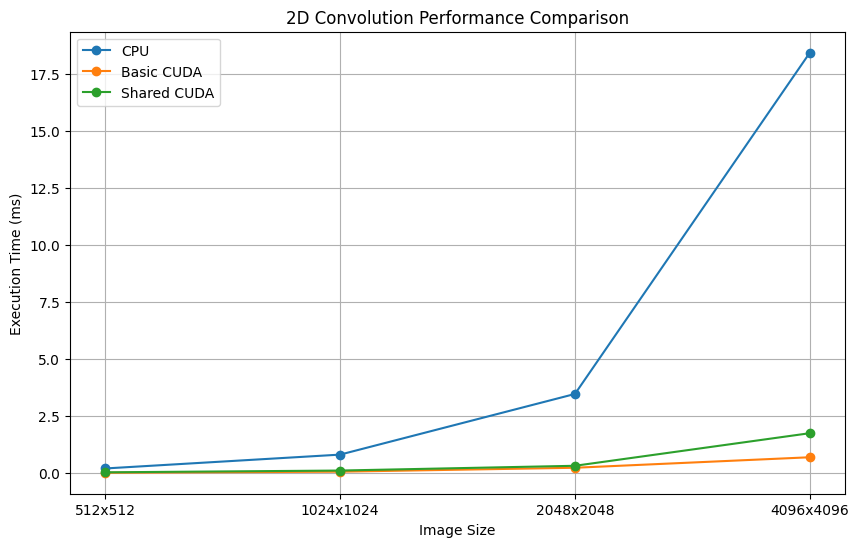

In [ ]:
import matplotlib.pyplot as plt

sizes = ["512x512", "1024x1024", "2048x2048", "4096x4096"]

cpu = [0.203, 0.810, 3.469, 18.4269]
basic_cuda = [0.016380, 0.061588, 0.233882, 0.694127]
shared_cuda = [0.034100, 0.111614, 0.320492, 1.749280]

plt.figure(figsize=(10, 6))

plt.plot(sizes, cpu, marker='o', label='CPU')
plt.plot(sizes, basic_cuda, marker='o', label='Basic CUDA')
plt.plot(sizes, shared_cuda, marker='o', label='Shared CUDA')

plt.xlabel("Image Size")
plt.ylabel("Execution Time (ms)")
plt.title("2D Convolution Performance Comparison")
plt.legend()
plt.grid(True)

plt.show()

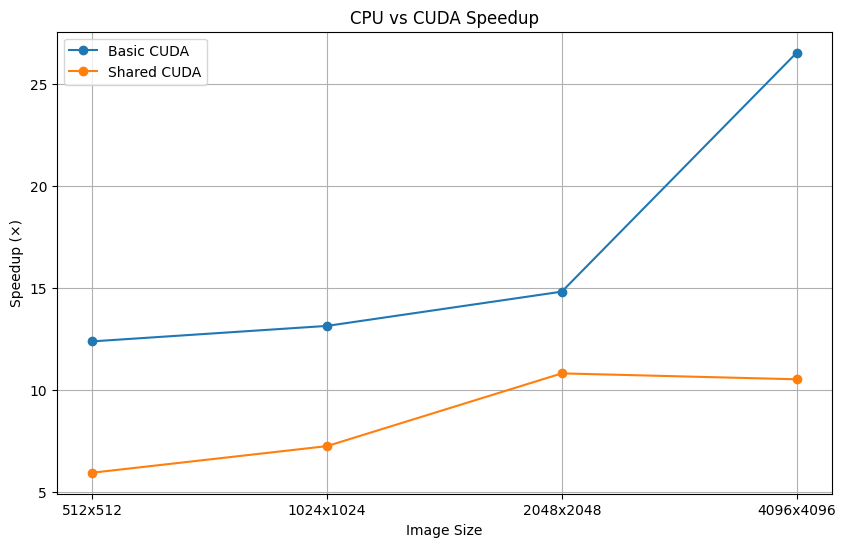

In [ ]:
import matplotlib.pyplot as plt

sizes = ["512x512", "1024x1024", "2048x2048", "4096x4096"]

basic_speedup = [12.393162, 13.151913, 14.832266, 26.546871]
shared_speedup = [5.953079, 7.257154, 10.823983, 10.533991]

plt.figure(figsize=(10, 6))

plt.plot(
    sizes,
    basic_speedup,
    marker='o',
    label='Basic CUDA'
)

plt.plot(
    sizes,
    shared_speedup,
    marker='o',
    label='Shared CUDA'
)

plt.xlabel("Image Size")
plt.ylabel("Speedup (×)")
plt.title("CPU vs CUDA Speedup")
plt.legend()
plt.grid(True)

plt.show()

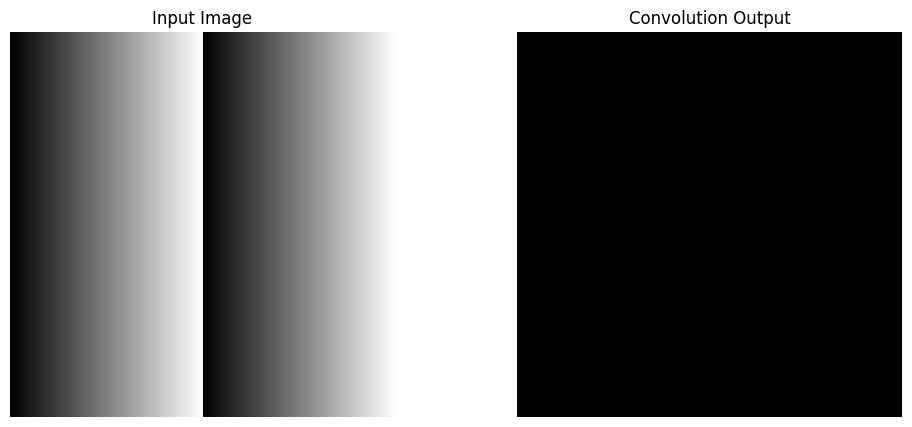

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

image = np.arange(512 * 512, dtype=np.float32).reshape(512, 512) % 256

kernel = np.array([
    [-1, -1, -1],
    [ 0,  0,  0],
    [ 1,  1,  1]
], dtype=np.float32)

output_height = image.shape[0] - kernel.shape[0] + 1
output_width = image.shape[1] - kernel.shape[1] + 1

output = np.zeros(
    (output_height, output_width),
    dtype=np.float32
)

for i in range(output_height):
    for j in range(output_width):
        region = image[i:i+3, j:j+3]
        output[i, j] = np.sum(region * kernel)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output, cmap="gray")
plt.title("Convolution Output")
plt.axis("off")

plt.show()

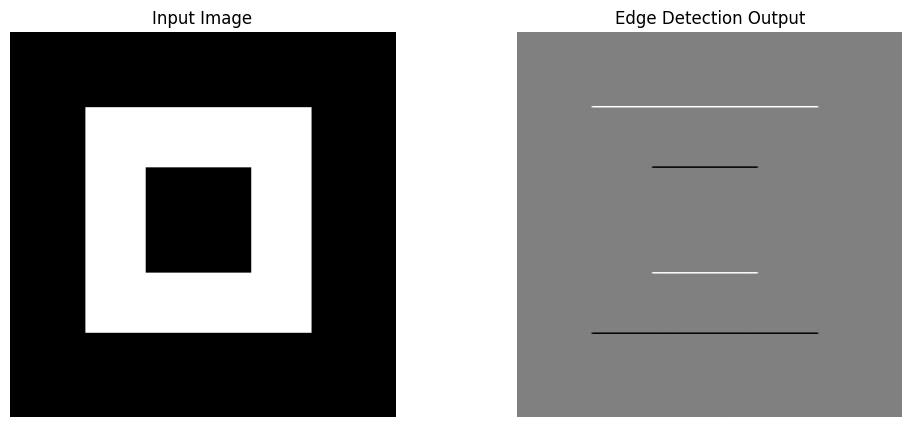

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Create a simple synthetic image with clear shapes
image = np.zeros((512, 512), dtype=np.float32)

image[100:400, 100:400] = 255
image[180:320, 180:320] = 0

# Edge detection kernel
kernel = np.array([
    [-1, -1, -1],
    [ 0,  0,  0],
    [ 1,  1,  1]
], dtype=np.float32)

output = np.zeros((510, 510), dtype=np.float32)

for i in range(510):
    for j in range(510):
        region = image[i:i+3, j:j+3]
        output[i, j] = np.sum(region * kernel)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output, cmap="gray")
plt.title("Edge Detection Output")
plt.axis("off")

plt.show()

## Final Performance Results

The 2D convolution implementation was evaluated using four image sizes:
512×512, 1024×1024, 2048×2048, and 4096×4096.

Three implementations were compared:

1. CPU-based convolution using C++ with `-O3` optimization
2. Basic CUDA convolution using one CUDA thread per output pixel
3. Shared-memory CUDA convolution using tiled shared-memory processing

### Key Findings

- Basic CUDA convolution achieved speedups ranging from **12.39× to 26.55×** compared with the CPU implementation.
- The highest measured speedup was **26.55×** for the 4096×4096 input.
- Shared-memory CUDA achieved speedups ranging from **5.95× to 10.82×**.
- For the tested 3×3 convolution, the shared-memory implementation was slower than the basic CUDA implementation.
- The shared-memory overhead decreased from approximately **108.18%** at 512×512 to **37.03%** at 2048×2048, but increased to **152.01%** at 4096×4096.
- CPU and CUDA outputs were verified for correctness, with a maximum absolute difference of **0.0** in the tested comparison.

### Conclusion

The experiments demonstrate that GPU parallelism can significantly accelerate 2D convolution compared with a CPU implementation. The basic CUDA implementation provided the best measured performance for the tested workload. The shared-memory experiment also demonstrates that GPU optimization techniques introduce additional synchronization and memory-management overhead and do not necessarily improve performance for every workload.

| Image Size | CPU (ms) | Basic CUDA (ms) | Shared CUDA (ms) | Basic CUDA Speedup | Shared CUDA Speedup |
|---|---:|---:|---:|---:|---:|
| 512×512 | 0.2030 | 0.016380 | 0.034100 | 12.39× | 5.95× |
| 1024×1024 | 0.8100 | 0.061588 | 0.111614 | 13.15× | 7.26× |
| 2048×2048 | 3.4690 | 0.233882 | 0.320492 | 14.83× | 10.82× |
| 4096×4096 | 18.4269 | 0.694127 | 1.749280 | 26.55× | 10.53× |